# Image Alignment And Stitching 

In [6]:
import urllib.request

# Download the images directly from OpenCV's repository
urllib.request.urlretrieve('https://raw.githubusercontent.com/opencv/opencv_extra/master/testdata/stitching/a1.png', 'church_left.png')
urllib.request.urlretrieve('https://raw.githubusercontent.com/opencv/opencv_extra/master/testdata/stitching/a2.png', 'church_center.png')
urllib.request.urlretrieve('https://raw.githubusercontent.com/opencv/opencv_extra/master/testdata/stitching/a3.png', 'church_right.png')

urllib.request.urlretrieve('https://raw.githubusercontent.com/opencv/opencv/master/samples/data/box_in_scene.png', 'distorted_scan.png')
urllib.request.urlretrieve('https://raw.githubusercontent.com/opencv/opencv/master/samples/data/box.png', 'flat_template.png')


('flat_template.png', <http.client.HTTPMessage at 0x1fe50139290>)

# Image Alignment

## How This Works?

This image alignment pipeline operates in six sequential stages, moving from raw pixel data to a mathematically flattened perspective.

1. Grayscale Conversion (cv2.cvtColor): The algorithm first strips away color data. Geometric feature detection relies purely on light-intensity gradients (sharp contrasts between dark and light areas), making RGB channels unnecessary and computationally expensive.
1. Feature Detection (cv2.ORB_create): The ORB (Oriented FAST and Rotated BRIEF) algorithm scans both images for "keypoints"—distinctive corners, edges, or patterns that maintain their unique signature regardless of scale or rotation. It then generates a mathematical descriptor (a fingerprint) for each point.
1. Feature Matching (cv2.DescriptorMatcher_create): The system compares the fingerprints from the distorted image to those in the flat template using "Hamming distance." It blindly pairs up points that have mathematically similar descriptors.
1. Filtering the Matches (sorted(matches)): Because the initial matching phase is aggressive, it produces many false positives (e.g., matching a random shadow on the desk to a dark letter on the page). The code sorts the matches by their confidence score and aggressively slices off the bottom 80%, keeping only the most robust pairings.
1. Homography & RANSAC (cv2.findHomography): This is the core mathematical engine. To calculate the 3D perspective shift between the two planes, the system needs a Homography matrix. It uses RANSAC (Random Sample Consensus) as a mathematical bouncer—it randomly samples small groups of points, calculates the perspective shift, and completely ignores any remaining "outlier" matches that contradict the physical consensus of the group.
1. Perspective Warping (cv2.warpPerspective): With the final Homography matrix calculated, the algorithm mathematically stretches, rotates, and squashes the distorted source image until its pixels perfectly overlay the geometry of the flat reference template.

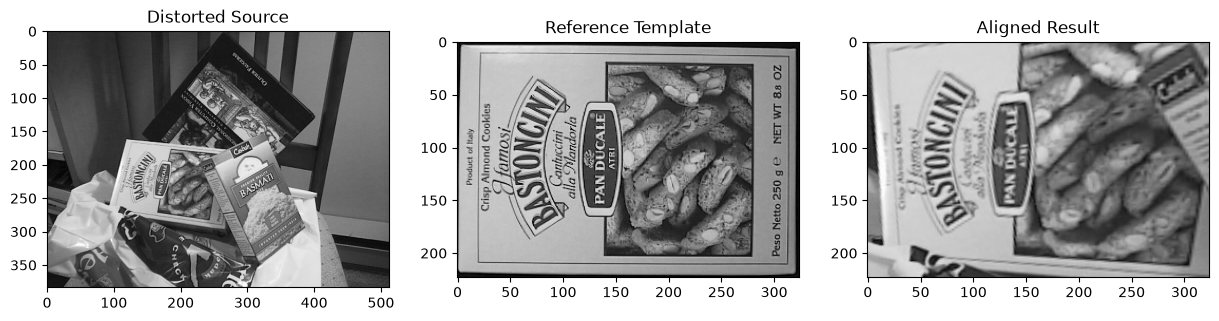

In [ ]:
###############################################
#           IMAGE ALIGNMENT
###############################################

import cv2
import numpy as np
import matplotlib.pyplot as plt

def align_images(im_src, im_reference, max_features=5000, keep_percent=0.2):
    # 1. Convert images to grayscale
    im1_gray = cv2.cvtColor(im_src, cv2.COLOR_BGR2GRAY)
    im2_gray = cv2.cvtColor(im_reference, cv2.COLOR_BGR2GRAY)
    
    # 2. Detect ORB features and compute descriptors
    orb = cv2.ORB_create(max_features)
    keypoints1, descriptors1 = orb.detectAndCompute(im1_gray, None)
    keypoints2, descriptors2 = orb.detectAndCompute(im2_gray, None)
    
    # 3. Match features using Hamming distance
    matcher = cv2.DescriptorMatcher_create(cv2.DESCRIPTOR_MATCHER_BRUTEFORCE_HAMMING)
    matches = matcher.match(descriptors1, descriptors2, None)
    
    # 4. Sort matches by score and remove the worst ones
    matches = sorted(matches, key=lambda x: x.distance)
    num_good_matches = int(len(matches) * keep_percent)
    matches = matches[:num_good_matches]
    
    # 5. Extract coordinates of the good matches
    points1 = np.zeros((len(matches), 2), dtype=np.float32)
    points2 = np.zeros((len(matches), 2), dtype=np.float32)
    
    for i, match in enumerate(matches):
        points1[i, :] = keypoints1[match.queryIdx].pt
        points2[i, :] = keypoints2[match.trainIdx].pt
        
    # 6. Find the Homography matrix using RANSAC
    # This matrix mathematically defines the perspective shift between the two images
    h, mask = cv2.findHomography(points1, points2, cv2.RANSAC)
    
    # 7. Warp the source image to align with the reference image
    height, width, channels = im_reference.shape
    im_aligned = cv2.warpPerspective(im_src, h, (width, height))
    
    return im_aligned, h

# --- Execution ---
# Load your images (e.g., a scanned document and a flat digital template)
img_distorted = cv2.imread('distorted_scan.png')
img_template = cv2.imread('flat_template.png')

aligned_img, homography_matrix = align_images(img_distorted, img_template)

plt.figure(figsize=(15, 7))
plt.subplot(1, 3, 1), plt.imshow(cv2.cvtColor(img_distorted, cv2.COLOR_BGR2RGB)), plt.title('Distorted Source')
plt.subplot(1, 3, 2), plt.imshow(cv2.cvtColor(img_template, cv2.COLOR_BGR2RGB)), plt.title('Reference Template')
plt.subplot(1, 3, 3), plt.imshow(cv2.cvtColor(aligned_img, cv2.COLOR_BGR2RGB)), plt.title('Aligned Result')
plt.show()

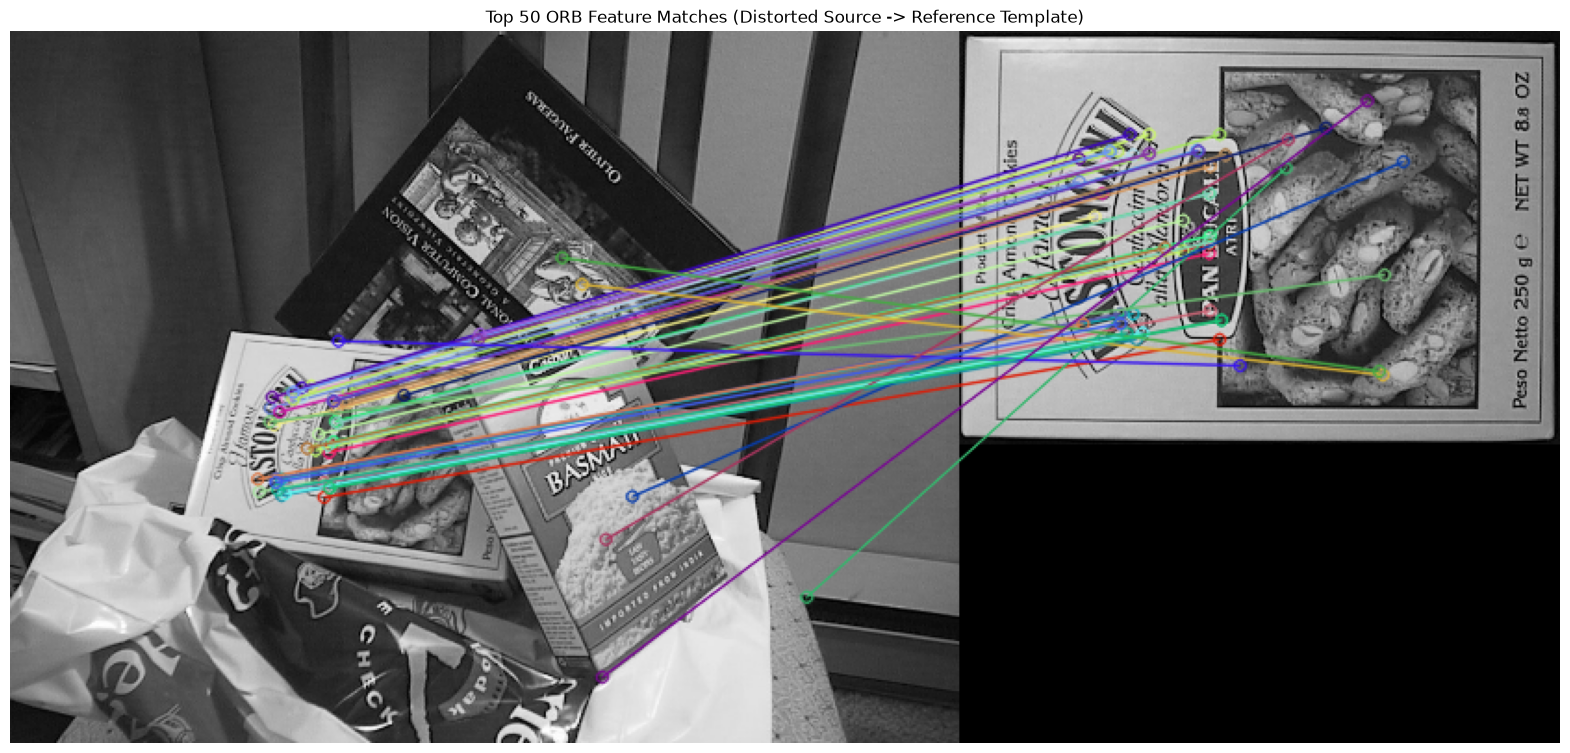

In [ ]:
###############################################
#           FEATURE MATCHING
###############################################

# 1. Load the images
img_distorted = cv2.imread('distorted_scan.png')
img_template = cv2.imread('flat_template.png')

if img_distorted is None or img_template is None:
    raise FileNotFoundError("Could not load images. Check your file paths!")

im1_gray = cv2.cvtColor(img_distorted, cv2.COLOR_BGR2GRAY)
im2_gray = cv2.cvtColor(img_template, cv2.COLOR_BGR2GRAY)

# 2. Detect and Compute ORB Features
orb = cv2.ORB_create(5000)
keypoints1, descriptors1 = orb.detectAndCompute(im1_gray, None)
keypoints2, descriptors2 = orb.detectAndCompute(im2_gray, None)

# 3. Match Features
matcher = cv2.DescriptorMatcher_create(cv2.DESCRIPTOR_MATCHER_BRUTEFORCE_HAMMING)
matches = matcher.match(descriptors1, descriptors2, None)

# 4. Sort by confidence and filter the best matches
matches = sorted(matches, key=lambda x: x.distance)
good_matches = matches[:int(len(matches) * 0.2)]

# 5. Visualize the Matches
# We only draw the top 50 matches; otherwise, the screen becomes a solid wall of chaotic lines.
# flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS ensures we only see keypoints that actually found a pair.
matched_vis = cv2.drawMatches(
    img_distorted, keypoints1, 
    img_template, keypoints2, 
    good_matches[:50], None, 
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# 6. Display the Visualization
plt.figure(figsize=(20, 10))
plt.imshow(cv2.cvtColor(matched_vis, cv2.COLOR_BGR2RGB))
plt.title("Top 50 ORB Feature Matches (Distorted Source -> Reference Template)")
plt.axis('off')
plt.show()

# Image Stitching

This panoramic stitching pipeline uses OpenCV's cv2.Stitcher class. Unlike the simple flat template alignment we did earlier, generating a seamless panorama is a massive mathematical optimization problem.

1. Feature Detection & Matching (Across all images): Just like the alignment script, the algorithm finds thousands of keypoints in every image. However, instead of matching A to B, it builds a massive web of matches: A to B, B to C, and A to C, figuring out exactly which images overlap with each other in the sequence.
1. Camera Model Estimation (Bundle Adjustment): The system mathematically works backward. By looking at how the keypoints move between images, it estimates the exact focal length of the camera and the 3D rotation angles (yaw, pitch, roll) for every single photograph.
1. Spherical/Cylindrical Warping: If you simply stretch three flat photos together using flat Homography matrices, the edges stretch out into a massive, distorted bow-tie shape. To fix this, the algorithm mathematically projects all the flat 2D images onto the inside of a 3D cylinder or sphere.
1. Exposure Compensation: If you take a photo facing the sun, it's bright. If you turn 45 degrees, the next photo is darker. The algorithm calculates these lighting differences and artificially brightens or darkens specific images so their overlapping zones have identical light levels.
1. Seam Finding: When two images overlap, the algorithm doesn't just draw a straight line down the middle. If a tree or a person is in the overlapping zone, a straight cut would create a "ghost" or chop them in half. The seam finder draws a jagged, optimized path through the pixels that avoids cutting through complex objects.
1. Multi-Band Blending: Finally, the algorithm blends the pixels across the jagged seams. It separates the image into high-frequency details (sharp edges) and low-frequency details (smooth colors like the sky), blending the sky smoothly over a wide area while keeping the sharp edges crisp and unblurred.

Loaded 3 images for stitching.
Stitching... (this may take a moment)
Panorama generated successfully!


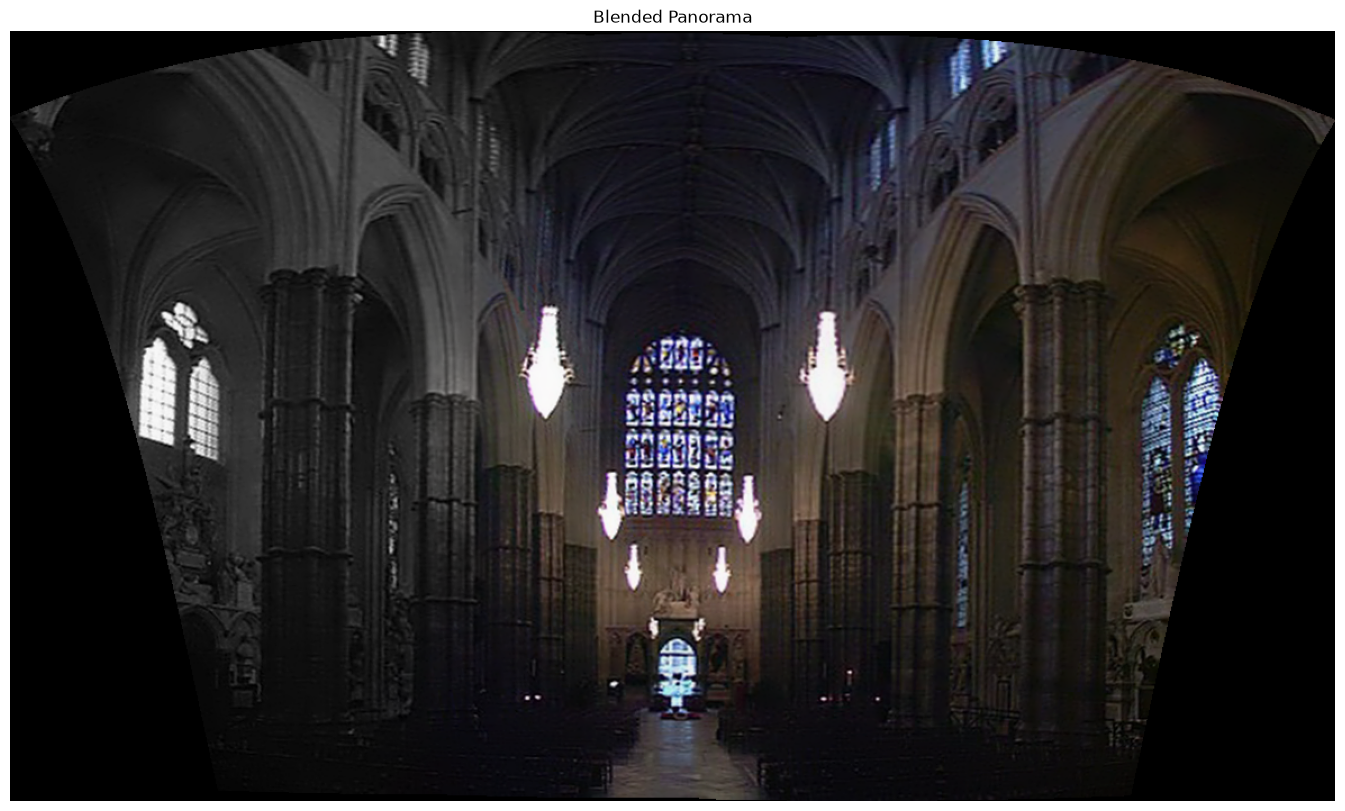

In [ ]:
###############################################
#           IMAGE STITCHING
###############################################

import cv2
import matplotlib.pyplot as plt

def stitch_panorama(image_paths):
    # 1. Load all images from the provided paths
    images = []
    for path in image_paths:
        img = cv2.imread(path)
        if img is None:
            print(f"Error: Could not read image {path}")
            return None
        images.append(img)
        
    print(f"Loaded {len(images)} images for stitching.")
    
    # 2. Initialize the OpenCV Stitcher class
    # PANORAMA mode assumes the images were taken by a rotating camera.
    # SCANS mode assumes the images were taken by a camera moving across a flat plane (like drone mapping).
    stitcher = cv2.Stitcher_create(cv2.Stitcher_PANORAMA)
    
    # 3. Perform the stitching pipeline
    print("Stitching... (this may take a moment)")
    status, stitched_img = stitcher.stitch(images)
    
    # 4. Handle success or error states
    if status == cv2.Stitcher_OK:
        print("Panorama generated successfully!")
        return stitched_img
    elif status == cv2.Stitcher_ERR_NEED_MORE_IMGS:
        print("Error: Not enough matching features between images.")
    elif status == cv2.Stitcher_ERR_HOMOGRAPHY_EST_FAIL:
        print("Error: Homography estimation failed. Images may not overlap enough.")
    elif status == cv2.Stitcher_ERR_CAMERA_PARAMS_ADJUST_FAIL:
        print("Error: Camera parameters adjustment failed.")
    
    return None

# --- Execution ---
# Provide a list of 2, 3, or more overlapping images
paths = ['church_left.png', 'church_center.png', 'church_right.png']

result = stitch_panorama(paths)

if result is not None:
    plt.figure(figsize=(20, 10))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title("Blended Panorama")
    plt.axis('off')
    plt.show()